In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)


def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    E_z = np.exp(Z)
    return E_z / np.sum(E_z, axis=1, keepdims=True)


def train(X, labels, K, lr=0.1, epochs=500):
    m, i = X.shape
    W = np.zeros((K, i))
    b = np.zeros(K)
    Y = np.eye(K)[labels]       
    ##eye는 K X K 행렬이고 Lables에 있는 정수는 행마다 one hot
    #encoding의 위치를 출력 (m, K) one-hot

    history = []

    for ep in range(epochs):
        # forward (루프 안!)
        Z = X @ W.T + b            # (m, K)
        P = softmax(Z)             # (m, K)

        # loss
        loss = -np.sum(Y * np.log(P + 1e-12)) / m
        history.append(loss)

        # backward
        # backward is always same in GLM
        dW = (P - Y).T @ X / m     # (K, i)
        db = (P - Y).mean(axis=0)  # (K,)
        assert dW.shape == W.shape and db.shape == b.shape

        # update
        W = W - lr * dW
        b = b - lr * db

    return W, b, history

def train_batch(X,batch_size, labels, K, lr=0.1, epochs=500,seed = 42):

    m, i = X.shape
    W = np.zeros((K, i))
    b = np.zeros(K)
    Y = np.eye(K)[labels]
    rng = np.random.default_rng(seed)

    history = []

    for epoch in range(epochs):

        idx = rng.permutation(m)

        for start in range(0,m,batch_size):

            batch = idx[start:start+batch_size]

            Xb = X[batch] #(B,i)
            Yb = Y[batch] #(B,K)
            
            B= len(batch)

            P = softmax(Xb @ W.T + b)             # (B, K)
            
            # backward
            # backward is always same in GLM
            dW = (P - Yb).T @ Xb / B     # (K, i)
            db = (P - Yb).mean(axis=0)  # (K,)
            assert dW.shape == W.shape and db.shape == b.shape

            #update
            W = W - lr * dW
            b = b - lr * db
            
        P_all = softmax(X @ W.T + b)
        history.append(-np.sum(Y * np.log(P_all + 1e-12)) / m)

    return W, b, history

def evaluate(X_test,labels_test,W,b):

    m = X_test.shape[0]
    Z =  X_test @ W.T + b
    P = softmax(Z)

    loss = -np.mean(np.log(P[np.arange(m), labels_test] + 1e-12))
    
    pred = P.argmax(axis=1)                        # (m,)
    acc = (pred == labels_test).mean()             # True/False의 평균 = 정답 비율

    return loss, acc

In [12]:
from sklearn.datasets import load_digits

d = load_digits()
X, labels = d.data / 16.0, d.target      # (1797, 64), 픽셀값 0~16 → 0~1
K = 10

rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
X,labels = X[idx],labels[idx]

n_train = int(len(X)*0.8)

X_train , X_test = X[:n_train],X[n_train:]
labels_train , labels_test = labels[:n_train],labels[n_train:]
print(X_train.shape, X_test.shape)       # (1437, 64) (360, 10 아님, 64)

(1437, 64) (360, 64)


full: train loss 0.176 acc 0.966 | test loss 0.174 acc 0.969
mini: train loss 0.058 acc 0.993 | test loss 0.077 acc 0.981


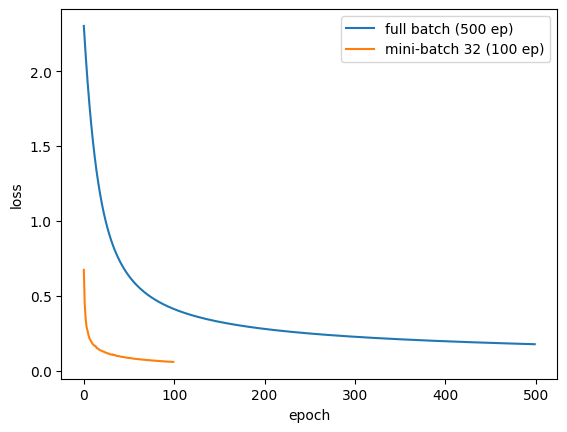

In [14]:
W1, b1, h1 = train(X_train, labels_train, K, lr=0.5, epochs=500)
W2, b2, h2 = train_batch(X_train, batch_size=32, labels=labels_train, K=K, lr=0.5, epochs=100)

for name, W, b in [("full", W1, b1), ("mini", W2, b2)]:
    tr = evaluate(X_train, labels_train, W, b)
    te = evaluate(X_test, labels_test, W, b)
    print(f"{name}: train loss {tr[0]:.3f} acc {tr[1]:.3f} | test loss {te[0]:.3f} acc {te[1]:.3f}")

plt.plot(h1, label="full batch (500 ep)")
plt.plot(h2, label="mini-batch 32 (100 ep)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

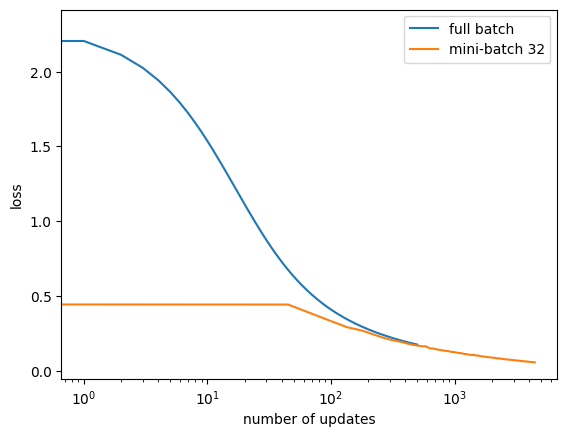

In [15]:
steps_per_epoch = int(np.ceil(len(X_train) / 32))     # 45
plt.plot(np.arange(len(h1)), h1, label="full batch")
plt.plot(np.arange(len(h2)) * steps_per_epoch, h2, label="mini-batch 32")
plt.xscale("log")                                      # 초반 차이가 잘 보이게
plt.xlabel("number of updates"); plt.ylabel("loss"); plt.legend(); plt.show()

In [16]:
def show_test_images(X_test, y_test, W, b, n=20, only_wrong=False):
    P = softmax(X_test @ W.T + b)         # (m, K)
    pred = P.argmax(axis=1)               # 예측 클래스
    conf = P.max(axis=1)                  # 예측 확신도

    idx = np.arange(len(X_test))
    if only_wrong:
        idx = idx[pred != y_test]         # 틀린 것만
    idx = idx[:n]

    cols = 5
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
    axes = np.atleast_1d(axes).ravel()

    for ax in axes:
        ax.axis("off")                    # 빈 칸 정리

    for ax, n_i in zip(axes, idx):
        ax.imshow(X_test[n_i].reshape(8, 8), cmap="gray_r")
        color = "green" if pred[n_i] == y_test[n_i] else "red"
        ax.set_title(f"true {y_test[n_i]} / pred {pred[n_i]}\n({conf[n_i]:.2f})",
                    color=color, fontsize=9)

    plt.tight_layout()
    plt.show()

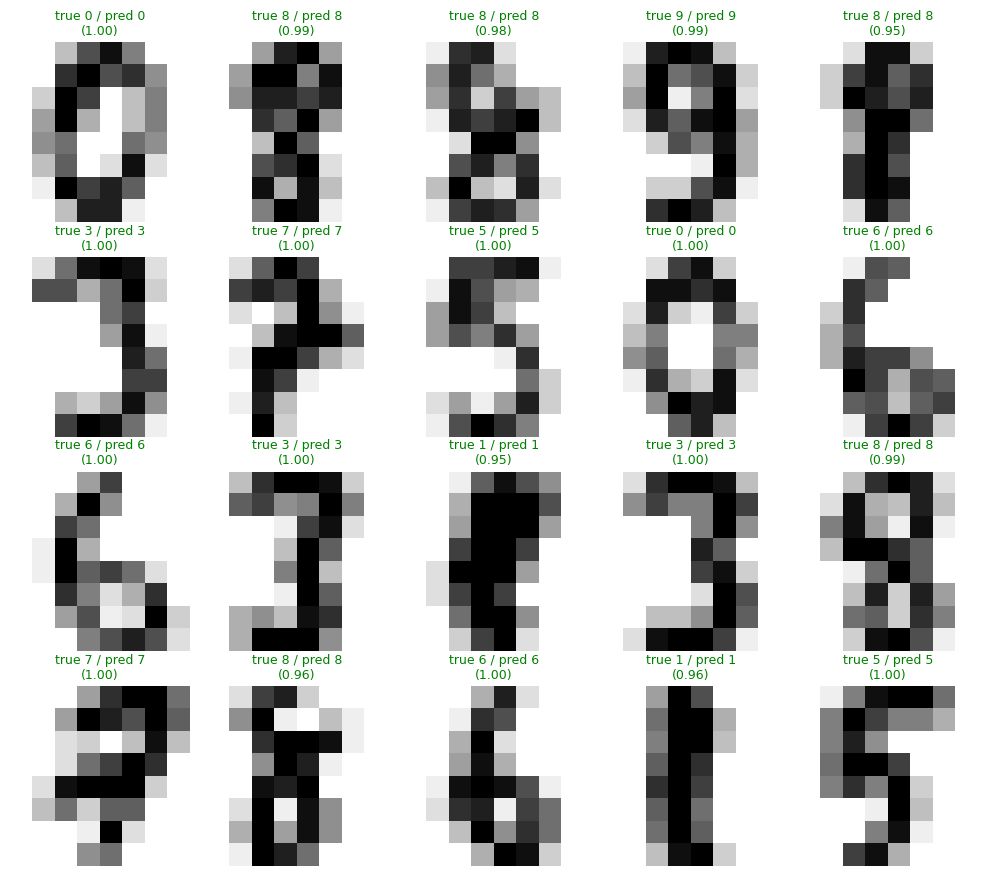

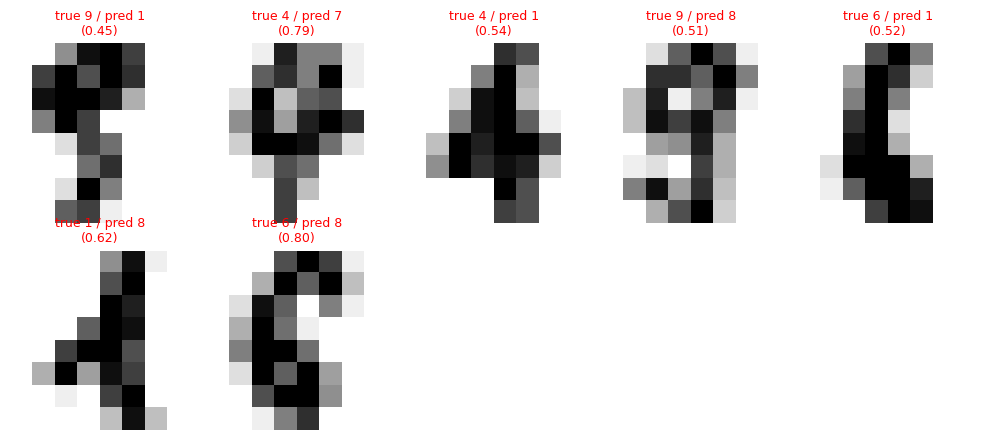

In [18]:
show_test_images(X_test, labels_test, W2, b2, n=20)                     # 처음 20장
show_test_images(X_test, labels_test, W2, b2, n=20, only_wrong=True)    # 틀린 것만